# OPSSAT-AD Dataset Anatomy

## Purpose

This notebook documents the structure and basic quality checks of `dataset.csv` and `segments.csv` for the project.

## What the Two Dataset Files Represent

`dataset.csv` is the fragment-level, tabular representation: each row describes one labelled telemetry fragment and contains its identifiers/metadata plus 18 provided handcrafted features (per the project data card). `segments.csv` is the raw time-series representation: each row is one timestamped telemetry value within a fragment.

The `segment` field identifies the fragment in both files, linking a `dataset.csv` feature row to its telemetry rows in `segments.csv`. In `segments.csv`, `timestamp` records when the observation was made and `value` is the telemetry measurement. The `channel` field identifies the telemetry channel. Exact timestamp conventions and the units/physical interpretation of `value` are ⚠️ Needs verification.

Both files carry fragment-related metadata, including `segment`, `channel` (in `dataset.csv` as well as `segments.csv`), `anomaly`, and `train`; `segments.csv` also includes `label` and `sampling`. These fields provide channel, anomaly-label, split, and sampling annotations at the represented row/fragment levels. The precise distinction and encoding semantics of `label` versus `anomaly`, and the units/meaning of `sampling`, are ⚠️ Needs verification. Feature columns in `dataset.csv` are the handcrafted fragment representation; meanings of individual feature columns are not inferred here.

## Field Roles

### `dataset.csv`

- **Label/anomaly:** `anomaly` is the anomaly-related label field; its exact encoding and semantics ⚠️ Needs verification.
- **Train/test split:** `train` records the published split membership (training versus test); the precise value mapping ⚠️ Needs verification.
- **Fragment identifier:** `segment` identifies the telemetry fragment.
- **Channel identifier:** `channel` identifies the source telemetry channel.
- **Handcrafted feature fields:** `duration`, `len`, `mean`, `var`, `std`, `kurtosis`, `skew`, `n_peaks`, `smooth10_n_peaks`, `smooth20_n_peaks`, `diff_peaks`, `diff2_peaks`, `diff_var`, `diff2_var`, `gaps_squared`, `len_weighted`, `var_div_duration`, and `var_div_len`. These are the 18 provided fragment-level handcrafted features identified in the project data card. This list is based on the documented feature count and the observed columns; meanings of individual features are not inferred here.
- **Other metadata:** `sampling` is present; its precise meaning/units ⚠️ Needs verification. The identifiers `segment` and `channel`, labels, split indicator, and `sampling` are kept distinct from the feature list above.

### `segments.csv`

- **Label/anomaly:** `label` and `anomaly` are label-related fields. Their exact relationship and encoding ⚠️ Needs verification; they are not assumed to be identical.
- **Train/test split:** `train` records split membership; the precise value mapping ⚠️ Needs verification.
- **Fragment identifier:** `segment` identifies the fragment.
- **Channel identifier:** `channel` identifies the telemetry channel.
- **Raw telemetry fields:** `timestamp` and `value` give the time and recorded telemetry value for each row. Timestamp conventions and physical units/interpretation ⚠️ Needs verification.
- **Other metadata:** `sampling` is present; its precise meaning/units ⚠️ Needs verification.

Identifiers such as `segment` and `channel` identify or group observations, while `train` describes the evaluation split. Treating them automatically as predictive inputs could let a model learn dataset organization or split membership instead of telemetry behaviour.

In [1]:
import os
import sys

print("Python version:", sys.version)
print("Current working directory:", os.getcwd())

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Current working directory: c:\Users\Mahesh Angadi\Desktop\SAT\explainable-satellite-telemetry-anomaly-detection\notebooks


In [2]:
import sys
print(sys.executable)
import pandas as pd


c:\Users\Mahesh Angadi\Desktop\SAT\explainable-satellite-telemetry-anomaly-detection\.venv\Scripts\python.exe


## File paths

The paths below point directly to the supplied files outside this Git repository.

In [3]:
DATASET_CSV_PATH = r"C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\dataset.csv"
SEGMENTS_CSV_PATH = r"C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\segments.csv"

print(f"dataset.csv: {DATASET_CSV_PATH}")
print(f"segments.csv: {SEGMENTS_CSV_PATH}")


dataset.csv: C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\dataset.csv
segments.csv: C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\segments.csv


## Loading the data

In [4]:
def load_csv_with_status(path, file_name):
    try:
        dataframe = pd.read_csv(path)
        print(f"{file_name} loaded successfully: True")
        return dataframe
    except Exception as error:
        print(f"{file_name} loaded successfully: False")
        print(f"{file_name} loading error: {error}")
        return None

dataset_df = load_csv_with_status(DATASET_CSV_PATH, "dataset.csv")
segments_df = load_csv_with_status(SEGMENTS_CSV_PATH, "segments.csv")


dataset.csv loaded successfully: True
segments.csv loaded successfully: True


## Dataset.csv inspection

In [5]:
if dataset_df is not None:
    print("Shape:", dataset_df.shape)
    print("\nExact column names:")
    print(dataset_df.columns.tolist())
    print("\nPandas dtypes:")
    print(dataset_df.dtypes)
    print("\nFirst 5 rows:")
    display(dataset_df.head())
    print("\nMissing-value counts:")
    print(dataset_df.isna().sum())


Shape: (2123, 23)

Exact column names:
['segment', 'anomaly', 'train', 'channel', 'sampling', 'duration', 'len', 'mean', 'var', 'std', 'kurtosis', 'skew', 'n_peaks', 'smooth10_n_peaks', 'smooth20_n_peaks', 'diff_peaks', 'diff2_peaks', 'diff_var', 'diff2_var', 'gaps_squared', 'len_weighted', 'var_div_duration', 'var_div_len']

Pandas dtypes:
segment               int64
anomaly               int64
train                 int64
channel                 str
sampling              int64
duration              int64
len                   int64
mean                float64
var                 float64
std                 float64
kurtosis            float64
skew                float64
n_peaks               int64
smooth10_n_peaks      int64
smooth20_n_peaks      int64
diff_peaks            int64
diff2_peaks           int64
diff_var            float64
diff2_var           float64
gaps_squared          int64
len_weighted          int64
var_div_duration    float64
var_div_len         float64
dtype: object

,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
0,1,1,1,CADC0872,1,279,280,8.533143e-07,3.494283e-10,0.000019,...,3,2,4,6,1.271176e-10,2.960666e-10,279,280,1.252431e-12,1.247958e-12
1,2,1,1,CADC0872,1,476,477,-3.639396e-06,6.476485e-10,0.000025,...,1,1,5,8,1.489383e-12,3.004752e-12,476,477,1.360606e-12,1.357754e-12
2,3,1,1,CADC0872,1,594,595,1.170788e-05,5.592877e-10,0.000024,...,2,2,2,3,4.112280e-12,1.029918e-11,594,595,9.415618e-13,9.399794e-13
3,4,1,1,CADC0872,1,271,272,8.486808e-07,5.466024e-10,0.000023,...,2,2,3,6,2.475760e-11,6.240985e-11,271,272,2.016983e-12,2.009568e-12
4,5,0,0,CADC0872,1,256,257,1.058485e-05,5.279023e-10,0.000023,...,1,1,78,87,5.547101e-13,7.035422e-13,256,257,2.062118e-12,2.054094e-12



Missing-value counts:
segment             0
anomaly             0
train               0
channel             0
sampling            0
duration            0
len                 0
mean                0
var                 0
std                 0
kurtosis            0
skew                0
n_peaks             0
smooth10_n_peaks    0
smooth20_n_peaks    0
diff_peaks          0
diff2_peaks         0
diff_var            0
diff2_var           0
gaps_squared        0
len_weighted        0
var_div_duration    0
var_div_len         0
dtype: int64


## Segments.csv inspection

In [6]:
if segments_df is not None:
    print("Shape:", segments_df.shape)
    print("\nExact column names:")
    print(segments_df.columns.tolist())
    print("\nPandas dtypes:")
    print(segments_df.dtypes)
    print("\nFirst 5 rows:")
    display(segments_df.head())
    print("\nMissing-value counts:")
    print(segments_df.isna().sum())


Shape: (303493, 8)

Exact column names:
['channel', 'timestamp', 'value', 'label', 'sampling', 'anomaly', 'segment', 'train']

Pandas dtypes:
channel          str
timestamp        str
value        float64
label            str
sampling       int64
anomaly        int64
segment        int64
train          int64
dtype: object

First 5 rows:


,channel,timestamp,value,label,sampling,anomaly,segment,train
0,CADC0872,2022-06-01T23:42:54.000Z,-0.000021,anomaly,1,1,1,1
1,CADC0872,2022-06-01T23:42:55.000Z,-0.000021,anomaly,1,1,1,1
2,CADC0872,2022-06-01T23:42:56.000Z,-0.000021,anomaly,1,1,1,1
3,CADC0872,2022-06-01T23:42:57.000Z,-0.000021,anomaly,1,1,1,1
4,CADC0872,2022-06-01T23:42:58.000Z,-0.000021,anomaly,1,1,1,1



Missing-value counts:
channel      0
timestamp    0
value        0
label        0
sampling     0
anomaly      0
segment      0
train        0
dtype: int64


## Initial verification summary

In [7]:
print("dataset.csv loaded successfully:", dataset_df is not None)
print("segments.csv loaded successfully:", segments_df is not None)

if dataset_df is not None:
    print("dataset.csv shape:", dataset_df.shape)
if segments_df is not None:
    print("segments.csv shape:", segments_df.shape)

print("This notebook only records directly observed file structure and missing-value counts.")


dataset.csv loaded successfully: True
segments.csv loaded successfully: True
dataset.csv shape: (2123, 23)
segments.csv shape: (303493, 8)
This notebook only records directly observed file structure and missing-value counts.


## Basic Data-Quality Checks

These checks use the existing in-memory `dataset_df` and `segments_df`; they do not load or alter source files.

### Data types and missing values

The exact per-column dtypes are shown in the inspection sections above. The existing `isna()` outputs show 0 missing values in each of the 23 `dataset_df` columns and each of the 8 `segments_df` columns. The compact dtype summary below groups columns by dtype; the missing-value summary reuses the already reported results.

### Exact duplicate rows

An exact duplicate means every value in a row matches another row. Repeated `segment` identifiers alone are not counted as duplicate rows.

### Label and anomaly counts

Counts and percentages are reported separately for each available label-related field. This describes the observed values without recoding them or assuming `label` and `anomaly` have the same meaning; their semantic relationship ⚠️ Needs verification.

### Fragment sample counts

The number of rows per `segment` in `segments_df` is the observed telemetry sample count. The summary includes minimum, maximum, mean, median, and quartiles. These counts are compared with `dataset_df.len` by `segment`; this comparison does not change either field.

### Basic numerical ranges

The tables report only observed minimum and maximum values: raw telemetry `value` in `segments_df` and all numeric columns in `dataset_df`. They are descriptive ranges, not spacecraft operating limits.

In [8]:
# Use the existing dataframes; no CSV loading occurs in this cell.
for frame_name, frame in (("dataset_df", dataset_df), ("segments_df", segments_df)):
    print(f"\n{frame_name} dtype summary (column counts by dtype):")
    dtype_counts = frame.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("column_count")
    display(dtype_counts)

print("\nMissing-value summary (from the per-column isna() results above):")
display(pd.DataFrame({
    "dataframe": ["dataset_df", "segments_df"],
    "columns_with_missing_values": [0, 0],
    "total_missing_values": [0, 0],
    "columns_checked": [dataset_df.shape[1], segments_df.shape[1]],
}))

print("\nExact duplicate row counts:")
display(pd.DataFrame({
    "dataframe": ["dataset_df", "segments_df"],
    "exact_duplicate_rows": [int(dataset_df.duplicated().sum()), int(segments_df.duplicated().sum())],
}))

print("\nLabel/anomaly counts and percentages (computed independently per field):")
for frame_name, frame, fields in (("dataset_df", dataset_df, ("anomaly",)), ("segments_df", segments_df, ("label", "anomaly"))):
    for field in fields:
        counts = frame[field].value_counts(dropna=False, sort=False)
        summary = pd.DataFrame({"count": counts, "percent": (100 * counts / len(frame)).round(2)})
        summary.index.name = field
        print(f"{frame_name}.{field}")
        display(summary)

print("\nObserved telemetry samples per segment in segments_df:")
segment_lengths = segments_df.groupby("segment").size().rename("observed_samples")
length_summary = segment_lengths.describe(percentiles=[0.25, 0.50, 0.75]).to_frame("sample_count").T
length_summary["median"] = segment_lengths.median()
display(length_summary[["count", "min", "max", "mean", "median", "25%", "50%", "75%"]].round(2))

print("\nComparison of dataset_df.len with observed segment sample counts:")
length_comparison = dataset_df[["segment", "len"]].merge(
    segment_lengths.reset_index(), on="segment", how="outer", indicator=True
)
both_present = length_comparison["_merge"].eq("both")
length_matches = length_comparison["len"].eq(length_comparison["observed_samples"])
display(pd.DataFrame({
    "comparison": ["dataset_df rows with matching segment", "both present and lengths equal", "both present but lengths differ", "dataset_df segment without raw rows", "raw segment without dataset_df row"],
    "count": [int(both_present.sum()), int((both_present & length_matches).sum()), int((both_present & ~length_matches).sum()), int(length_comparison["_merge"].eq("left_only").sum()), int(length_comparison["_merge"].eq("right_only").sum())],
}))

print("\nObserved raw telemetry value range in segments_df:")
display(segments_df["value"].agg(["min", "max"]).to_frame("value").T)

print("\nObserved min/max for numeric columns in dataset_df:")
numeric_dataset = dataset_df.select_dtypes(include="number")
display(numeric_dataset.agg(["min", "max"]).T.rename(columns={"min": "minimum", "max": "maximum"}))


dataset_df dtype summary (column counts by dtype):


,column_count
dtype,
int64,13
float64,9
str,1



segments_df dtype summary (column counts by dtype):


,column_count
dtype,
int64,4
str,3
float64,1



Missing-value summary (from the per-column isna() results above):


...

,comparison,count
0,dataset_df rows with matching segment,2123
1,both present and lengths equal,2123
2,both present but lengths differ,0
3,dataset_df segment without raw rows,0
4,raw segment without dataset_df row,0



Observed raw telemetry value range in segments_df:


,min,max
value,-0.000101,1.5708



Observed min/max for numeric columns in dataset_df:


,minimum,maximum
segment,1.000000e+00,2123.000000
anomaly,0.000000e+00,1.000000
train,0.000000e+00,1.000000
sampling,1.000000e+00,5.000000
duration,3.500000e+01,1335.000000
len,8.000000e+00,1040.000000
mean,-3.833030e-05,1.118632
var,1.422763e-11,0.272480
std,3.771953e-06,0.521996
kurtosis,-1.858813e+00,31.201842


### Task 3 Interpretation

The existing inspection shows that both dataframes have populated dtype and per-column missing-value results, with no missing values observed in either file. The check output above records exact-row duplicates, observed label values, fragment sample counts, and numerical ranges. These are descriptions of the supplied tables; they do not establish why a label was assigned or whether a telemetry value is operationally safe.

## Representative Telemetry Fragment Plots

The cell below uses the already-loaded `segments_df` to plot up to three complete, distinct fragments from each observed `anomaly` category (0 and 1). It orders samples by timestamp and uses timestamps as the horizontal axis. The categories are labeled by their observed values because their exact semantic mapping ⚠️ Needs verification.


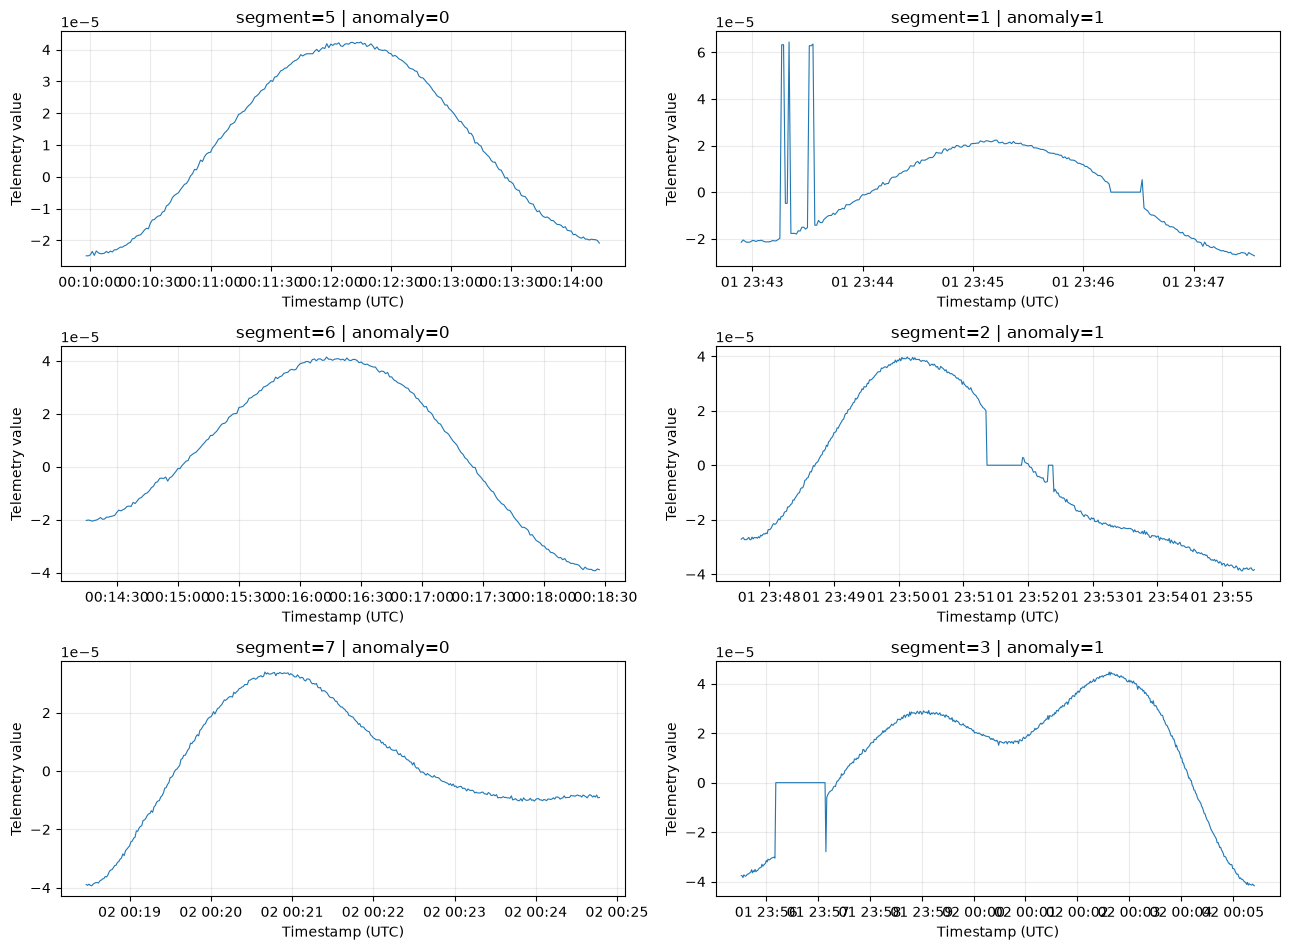

In [9]:
import matplotlib.pyplot as plt

# Select fragments whose observed anomaly value is consistent within the fragment.
segment_anomaly = segments_df.groupby("segment")["anomaly"].agg(["nunique", "first"])
selected_by_anomaly = {}
for anomaly_value in (0, 1):
    eligible_ids = segment_anomaly.index[
        segment_anomaly["nunique"].eq(1) & segment_anomaly["first"].eq(anomaly_value)
    ].tolist()
    selected_by_anomaly[anomaly_value] = eligible_ids[:3]
    if len(selected_by_anomaly[anomaly_value]) < 2:
        raise ValueError(
            f"Need at least two complete fragments with anomaly={anomaly_value}; "
            f"found {len(selected_by_anomaly[anomaly_value])}."
        )

n_examples = max(len(segment_ids) for segment_ids in selected_by_anomaly.values())
fig, axes = plt.subplots(n_examples, 2, figsize=(13, 3.2 * n_examples), squeeze=False)

for column, anomaly_value in enumerate((0, 1)):
    for row, segment_id in enumerate(selected_by_anomaly[anomaly_value]):
        fragment = segments_df.loc[segments_df["segment"].eq(segment_id)].copy()
        fragment["_plot_timestamp"] = pd.to_datetime(fragment["timestamp"], utc=True)
        fragment = fragment.sort_values("_plot_timestamp", kind="stable")

        ax = axes[row, column]
        ax.plot(fragment["_plot_timestamp"], fragment["value"], linewidth=0.8)
        ax.set_title(f"segment={segment_id} | anomaly={anomaly_value}")
        ax.set_xlabel("Timestamp (UTC)")
        ax.set_ylabel("Telemetry value")
        ax.grid(True, alpha=0.25)

    for row in range(len(selected_by_anomaly[anomaly_value]), n_examples):
        axes[row, column].set_visible(False)

fig.tight_layout()
plt.show()


The panels show complete telemetry-value traces over timestamp for distinct fragments in each observed anomaly category. They support visual comparison of the selected examples only; apparent differences do not establish a physical spacecraft fault or root cause.

### Visual Observation

The plotted traces make the within-fragment changes in telemetry value over time visible for the selected `anomaly=0` and `anomaly=1` examples. Any differences are descriptive observations about these examples and do not prove physical faults or root causes. ⚠️ Needs verification: exact semantic mapping of the anomaly encoding.


## Raw Telemetry vs Handcrafted Features

`segments.csv` stores telemetry as a sample-level temporal representation: each row contains a sample's `timestamp` and `value`, organized into fragments by `segment`. Keeping these timestamped samples preserves their temporal sequence.

`dataset.csv` provides a fragment-level handcrafted-feature representation. Each row describes a fragment and includes metadata, labels, split information, and the provided numerical features. Features such as `mean`, `var`, `std`, `kurtosis`, `skew`, and `n_peaks` summarize characteristics of a fragment; they do not preserve every sample in temporal order. These documented features are distinct from identifier, label, split, and other metadata fields, and this note does not designate all numeric columns as model inputs.

This distinction will be important when later comparing classical feature-based approaches with temporal modelling.

## Exploratory Data Analysis — Channel Behaviour

This section examines the nine observed telemetry channels using the existing `segments_df` dataframe. Tables compare the observed `anomaly=0` and `anomaly=1` categories without assigning unverified semantic labels. Friday's dataset-wide check found no explicit missing values; the table below gives the channel-level missingness overview for timestamps and telemetry values. The `sampling` field's exact meaning remains ⚠️ Needs verification.

The summaries describe the selected dataset. They do not establish physical limits, fault causes, or final preprocessing/model-input decisions.

Channel-level missingness (Friday's full-table check found no missing values):


,sample_rows,missing_timestamps,missing_values
channel,,,
CADC0872,66819,0,0
CADC0873,68289,0,0
CADC0874,58719,0,0
CADC0884,11810,0,0
CADC0886,373,0,0
CADC0888,11640,0,0
CADC0890,549,0,0
CADC0892,49782,0,0
CADC0894,35512,0,0


Telemetry-value distribution by channel and observed anomaly value:


,channel,anomaly,sample_count,mean,std,median,minimum,maximum,q25,q75
0,CADC0872,0,42453,1.020000e-06,0.000022,9.800000e-07,-0.000050,0.000050,-0.000016,0.000019
1,CADC0872,1,24366,9.300000e-07,0.000020,0.000000e+00,-0.000088,0.000065,-0.000014,0.000017
2,CADC0873,0,45840,-7.200000e-07,0.000022,-6.000000e-07,-0.000052,0.000049,-0.000018,0.000016
3,CADC0873,1,22449,-1.980000e-06,0.000019,0.000000e+00,-0.000101,0.000060,-0.000017,0.000012
4,CADC0874,0,23275,3.520000e-06,0.000021,4.330000e-06,-0.000048,0.000048,-0.000014,0.000021
5,CADC0874,1,35444,3.040000e-06,0.000019,9.900000e-07,-0.000048,0.000101,-0.000011,0.000018
6,CADC0884,0,11810,4.707211e-01,0.391373,4.182350e-01,0.000000,1.570800,0.076915,0.818277
7,CADC0886,0,286,1.784202e-01,0.224700,3.668960e-02,0.000000,0.721150,0.000000,0.385449
8,CADC0886,1,87,1.985317e-01,0.122355,2.242500e-01,0.000000,0.402829,0.082625,0.291838
9,CADC0888,0,8886,2.872134e-01,0.358295,6.689150e-02,0.000000,1.301890,0.000000,0.579478


Observed telemetry-value ranges by channel:


...

Observed intervals between timestamp-ordered samples within fragments, in seconds:


,channel,anomaly,interval_count,minimum_seconds,median_seconds,maximum_seconds,q25_seconds,q75_seconds
0,CADC0872,0,42038,1.0,1.0,7.0,1.0,1.0
1,CADC0872,1,24235,1.0,1.0,130.0,1.0,1.0
2,CADC0873,0,45352,1.0,1.0,7.0,1.0,5.0
3,CADC0873,1,22344,1.0,1.0,127.0,1.0,1.0
4,CADC0874,0,23150,1.0,1.0,7.0,1.0,5.0
5,CADC0874,1,35375,1.0,1.0,125.0,1.0,1.0
6,CADC0884,0,11652,4.0,5.0,15.0,5.0,5.0
7,CADC0886,0,278,5.0,5.0,5.0,5.0,5.0
8,CADC0886,1,84,5.0,5.0,130.0,5.0,5.0
9,CADC0888,0,8694,4.0,5.0,15.0,5.0,5.0


Fragment sample counts by channel and observed anomaly category:


fragment_count  minimum  median    mean  maximum
channel  anomaly_category                                                  
CADC0872 anomaly=0                    415       14    48.0  102.30      687
         anomaly=1                    131       15   179.0  186.00      595
CADC0873 anomaly=0                    488       14    48.0   93.93      478
         anomaly=1                    105       12   193.0  213.80      673
CADC0874 anomaly=0                    125       37    78.0  186.20      780
         anomaly=1                     69       38   493.0  513.68     1040
CADC0884 anomaly=0                    158       17    81.0   74.75      173
CADC0886 anomaly=0                      8       29    37.5   35.75       39
         anomaly=1                      3       15    36.0   29.00       36
CADC0888 anomaly=0                    192        8    48.5   46.28       97
         anomaly=1                     60       10    43.0   45.90       84
CADC0890 anomaly=0                      3       48    48.0   49.00       51
         anomaly=1                     11       19    40.0   36.55       48
CADC0892 anomaly=0                    177       38   244.0  240.38      470
         anomaly=1                     34       27   187.5  212.76      401
CADC0894 anomaly=0                    123       36    53.0  227.51      827
         anomaly=1                     21       21   405.0  358.48      630

Fragments with mixed or missing anomaly values: 0


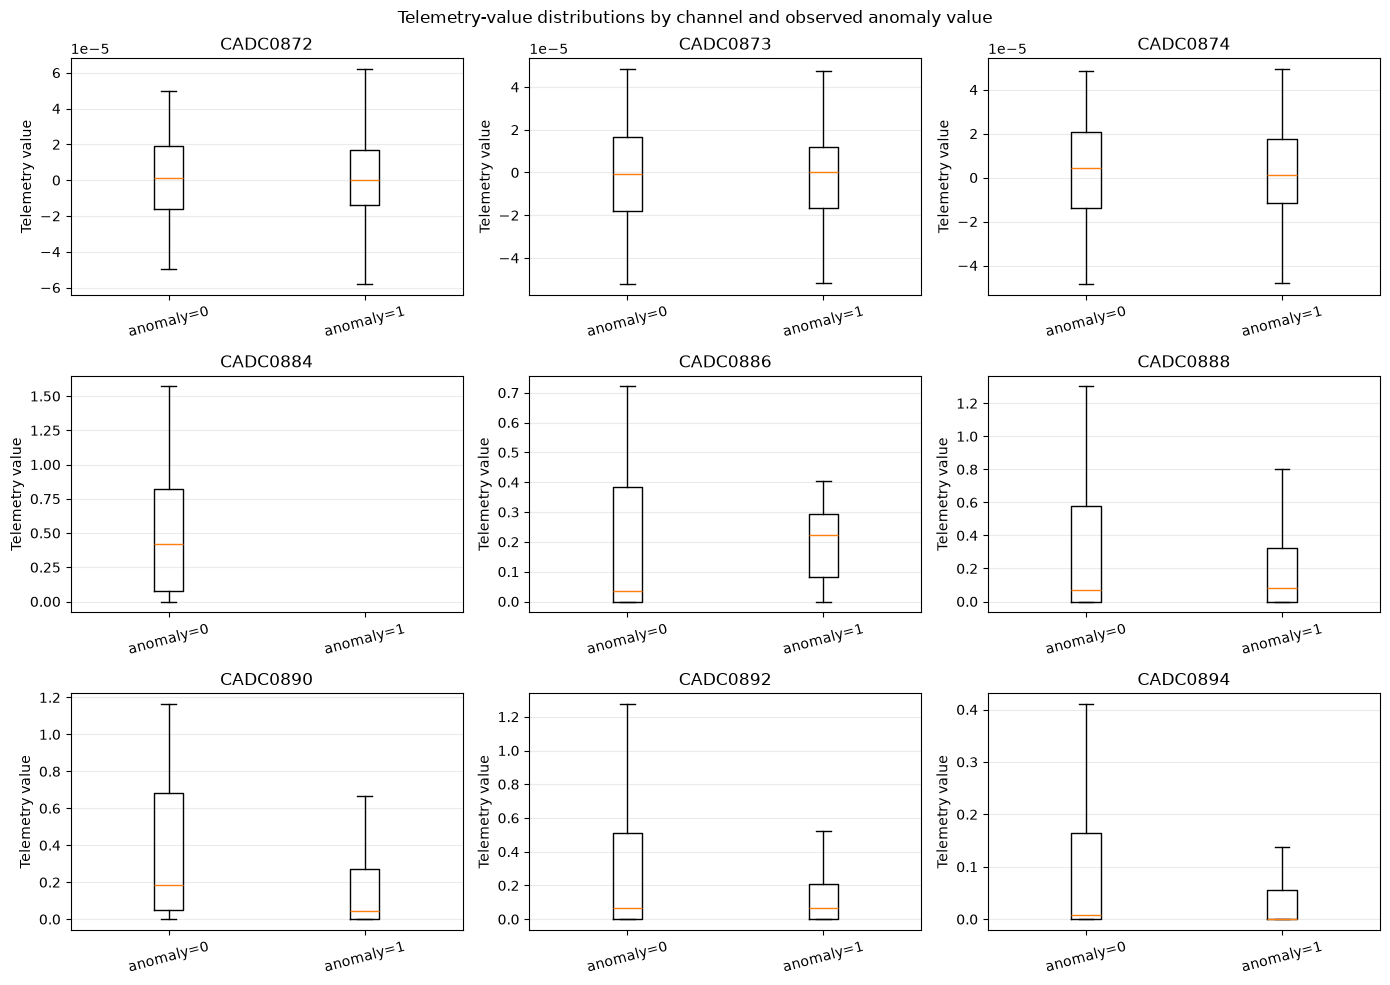

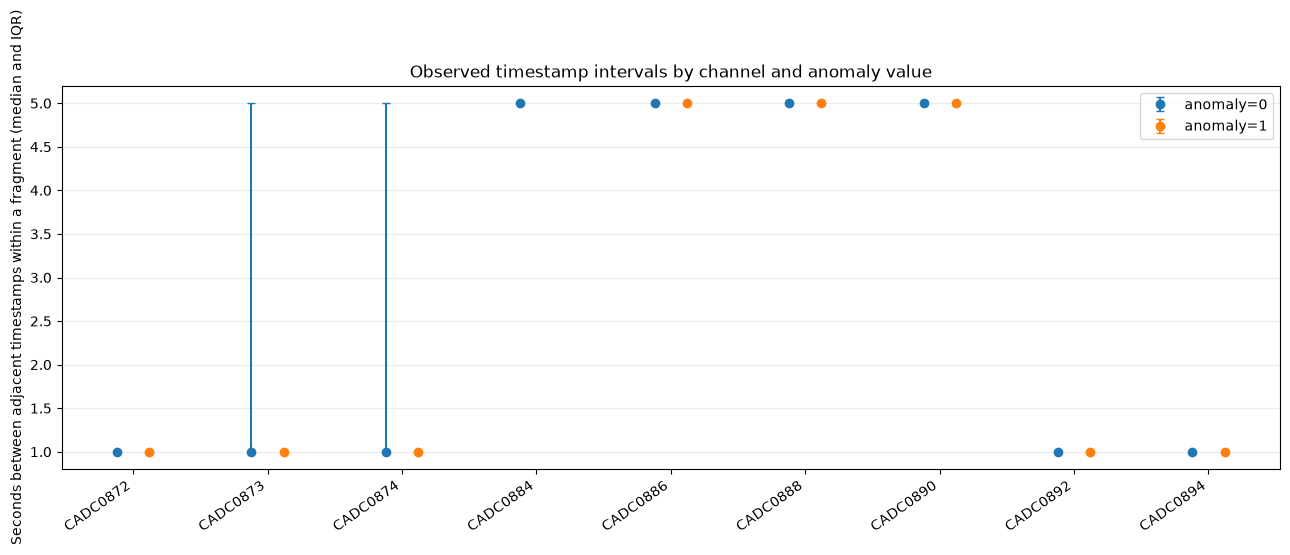

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Channel-level missingness, carrying forward Friday's full-table result.
channel_missingness = segments_df.groupby("channel", dropna=False).agg(
    sample_rows=("segment", "size"),
    missing_timestamps=("timestamp", lambda values: int(values.isna().sum())),
    missing_values=("value", lambda values: int(values.isna().sum())),
)
print("Channel-level missingness (Friday's full-table check found no missing values):")
display(channel_missingness)

# Distribution summaries and observed value ranges by channel and anomaly category.
channel_anomaly = segments_df.groupby(["channel", "anomaly"], dropna=False)["value"]
value_distribution = channel_anomaly.agg(
    sample_count="count", mean="mean", std="std", median="median", minimum="min", maximum="max"
)
value_quartiles = channel_anomaly.quantile([0.25, 0.75]).unstack()
value_quartiles.columns = ["q25", "q75"]
value_distribution = value_distribution.join(value_quartiles).reset_index()
print("Telemetry-value distribution by channel and observed anomaly value:")
display(value_distribution.round(8))

channel_ranges = segments_df.groupby("channel")["value"].agg(
    sample_count="count", minimum="min", maximum="max"
)
print("Observed telemetry-value ranges by channel:")
display(channel_ranges)

# Record observed values of the sampling field without assigning them a meaning.
sampling_values = segments_df.groupby(["channel", "sampling"], dropna=False).agg(
    sample_rows=("segment", "size"), fragment_count=("segment", "nunique")
).reset_index()
print("Observed sampling-field values by channel (semantics/units not inferred):")
display(sampling_values)

# Timestamp intervals are measured only between adjacent samples within a fragment.
ordered = segments_df.assign(_timestamp=pd.to_datetime(segments_df["timestamp"], utc=True))
ordered = ordered.sort_values(["channel", "segment", "_timestamp"], kind="stable")
ordered["interval_seconds"] = ordered.groupby(["channel", "segment"], sort=False)["_timestamp"].diff().dt.total_seconds()
interval_group = ordered.groupby(["channel", "anomaly"], dropna=False)["interval_seconds"]
interval_summary = interval_group.agg(
    interval_count="count", minimum_seconds="min", median_seconds="median", maximum_seconds="max"
)
interval_quartiles = interval_group.quantile([0.25, 0.75]).unstack()
interval_quartiles.columns = ["q25_seconds", "q75_seconds"]
interval_summary = interval_summary.join(interval_quartiles).reset_index()
print("Observed intervals between timestamp-ordered samples within fragments, in seconds:")
display(interval_summary.round(3))

# Fragment lengths by channel and observed anomaly category.
fragment_lengths = segments_df.groupby(["channel", "segment"], sort=False).size().rename("sample_count").reset_index()
fragment_labels = segments_df.groupby(["channel", "segment"], sort=False)["anomaly"].agg(
    anomaly_unique_values="nunique", anomaly_observed="first"
).reset_index()
fragment_lengths = fragment_lengths.merge(fragment_labels, on=["channel", "segment"], how="left")
fragment_lengths["anomaly_category"] = [
    f"anomaly={int(value)}" if unique_count == 1 and pd.notna(value) else "mixed/unknown"
    for unique_count, value in zip(fragment_lengths["anomaly_unique_values"], fragment_lengths["anomaly_observed"])
]
length_summary = fragment_lengths.groupby(["channel", "anomaly_category"])["sample_count"].agg(
    fragment_count="count", minimum="min", median="median", mean="mean", maximum="max"
)
print("Fragment sample counts by channel and observed anomaly category:")
display(length_summary.round(2))
print("Fragments with mixed or missing anomaly values:", int(fragment_lengths["anomaly_category"].eq("mixed/unknown").sum()))

# Figure 1: channel-level telemetry-value distributions for the observed categories.
channels = sorted(segments_df["channel"].dropna().unique().tolist())
fig, axes = plt.subplots(3, 3, figsize=(14, 10), squeeze=False)
for ax, channel in zip(axes.flat, channels):
    groups = [
        segments_df.loc[
            segments_df["channel"].eq(channel) & segments_df["anomaly"].eq(anomaly_value), "value"
        ].dropna().to_numpy(dtype=float)
        for anomaly_value in (0, 1)
    ]
    ax.boxplot(groups, tick_labels=["anomaly=0", "anomaly=1"], showfliers=False)
    ax.set_title(str(channel))
    ax.set_ylabel("Telemetry value")
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Telemetry-value distributions by channel and observed anomaly value")
fig.tight_layout()
plt.show()

# Figure 2: median observed timestamp interval with an IQR bar, by channel/category.
fig, ax = plt.subplots(figsize=(13, 5))
channel_positions = {channel: index for index, channel in enumerate(channels)}
for offset, anomaly_value in zip((-0.12, 0.12), (0, 1)):
    subset = interval_summary.loc[interval_summary["anomaly"].eq(anomaly_value)].set_index("channel")
    present = [channel for channel in channels if channel in subset.index and pd.notna(subset.loc[channel, "median_seconds"])]
    x = np.array([channel_positions[channel] + offset for channel in present], dtype=float)
    medians = subset.loc[present, "median_seconds"].to_numpy(dtype=float)
    lower = medians - subset.loc[present, "q25_seconds"].to_numpy(dtype=float)
    upper = subset.loc[present, "q75_seconds"].to_numpy(dtype=float) - medians
    ax.errorbar(x, medians, yerr=np.vstack([lower, upper]), marker="o", capsize=3, linestyle="none", label=f"anomaly={anomaly_value}")
ax.set_xticks(np.arange(len(channels)), channels, rotation=35, ha="right")
ax.set_ylabel("Seconds between adjacent timestamps within a fragment (median and IQR)")
ax.set_title("Observed timestamp intervals by channel and anomaly value")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


### EDA Summary

- The nine observed channels have no missing `timestamp` or `value` entries, consistent with Friday's full-table missingness check. Sample counts differ substantially by channel, from 373 rows for CADC0886 to 68,289 for CADC0873.
- Observed channel ranges differ: the overall minimum is -0.000101 (CADC0873) and the overall maximum is 1.5708 (CADC0884 and CADC0892). Telemetry units and physical limits are not established here.
- The `sampling` field contains observed values 1 and 5; its meaning remains ⚠️ Needs verification. Median timestamp intervals within fragments are 1 or 5 seconds by channel/category, while some observed intervals extend to 130 seconds.
- Fragment sample counts and telemetry-value distributions vary by channel and observed anomaly category. For example, median fragment length for CADC0874 is 78 samples at `anomaly=0` and 493 at `anomaly=1`; CADC0884 has no `anomaly=1` samples in this file.
- These are descriptive comparisons of recorded categories. They do not establish the semantic meaning of the anomaly encoding, physical faults, or root causes.

In [11]:
raw_summary = (
    segments_df.groupby("segment")["value"]
    .agg(["count", "mean", "var", "std"])
    .reset_index()
    .rename(columns={
        "count": "raw_len",
        "mean": "raw_mean",
        "var": "raw_var",
        "std": "raw_std"
    })
)

comparison = dataset_df[
    ["segment", "len", "mean", "var", "std"]
].merge(
    raw_summary,
    on="segment",
    how="inner"
)

comparison["len_diff"] = comparison["len"] - comparison["raw_len"]
comparison["mean_diff"] = comparison["mean"] - comparison["raw_mean"]
comparison["var_diff"] = comparison["var"] - comparison["raw_var"]
comparison["std_diff"] = comparison["std"] - comparison["raw_std"]

display(comparison.head())

,segment,len,mean,var,std,raw_len,raw_mean,raw_var,raw_std,len_diff,mean_diff,var_diff,std_diff
0,1,280,8.533143e-07,3.494283e-10,0.000019,280,8.533144e-07,3.506807e-10,0.000019,0,-2.117582e-22,-1.252431e-12,-3.347004e-08
1,2,477,-3.639396e-06,6.476485e-10,0.000025,477,-3.639396e-06,6.490091e-10,0.000025,0,-1.694066e-21,-1.360606e-12,-2.671805e-08
2,3,595,1.170788e-05,5.592877e-10,0.000024,595,1.170788e-05,5.602293e-10,0.000024,0,0.000000e+00,-9.415618e-13,-1.989842e-08
3,4,272,8.486808e-07,5.466024e-10,0.000023,272,8.486808e-07,5.486194e-10,0.000023,0,7.411538e-22,-2.016983e-12,-4.309594e-08
4,5,257,1.058485e-05,5.279023e-10,0.000023,257,1.058485e-05,5.299644e-10,0.000023,0,0.000000e+00,-2.062118e-12,-4.483150e-08


In [12]:
comparison[
    ["len_diff", "mean_diff", "var_diff", "std_diff"]
].abs().max()

len_diff     0.000000e+00
mean_diff    2.220446e-16
var_diff     8.432579e-03
std_diff     1.315068e-02
dtype: float64

In [13]:
raw_summary_ddof0 = (
    segments_df.groupby("segment")["value"]
    .agg(
        raw_len="count",
        raw_mean="mean",
        raw_var=lambda x: x.var(ddof=0),
        raw_std=lambda x: x.std(ddof=0)
    )
    .reset_index()
)

comparison_ddof0 = dataset_df[
    ["segment", "len", "mean", "var", "std"]
].merge(
    raw_summary_ddof0,
    on="segment",
    how="inner"
)

comparison_ddof0["len_diff"] = (
    comparison_ddof0["len"] - comparison_ddof0["raw_len"]
)

comparison_ddof0["mean_diff"] = (
    comparison_ddof0["mean"] - comparison_ddof0["raw_mean"]
)

comparison_ddof0["var_diff"] = (
    comparison_ddof0["var"] - comparison_ddof0["raw_var"]
)

comparison_ddof0["std_diff"] = (
    comparison_ddof0["std"] - comparison_ddof0["raw_std"]
)

display(
    comparison_ddof0[
        ["segment", "len_diff", "mean_diff", "var_diff", "std_diff"]
    ].head()
)

,segment,len_diff,mean_diff,var_diff,std_diff
0,1,0,-2.117582e-22,5.169879e-26,0.000000e+00
1,2,0,-1.694066e-21,0.000000e+00,3.388132e-21
2,3,0,0.000000e+00,0.000000e+00,3.388132e-21
3,4,0,7.411538e-22,-1.033976e-25,-3.388132e-21
4,5,0,0.000000e+00,0.000000e+00,0.000000e+00


In [14]:
comparison_ddof0[
    ["len_diff", "mean_diff", "var_diff", "std_diff"]
].abs().max()

len_diff     0.000000e+00
mean_diff    2.220446e-16
var_diff     9.974660e-17
std_diff     9.714451e-17
dtype: float64

## Raw Telemetry vs Handcrafted-Feature Comparison

For each telemetry fragment, the raw samples in `segments.csv` were grouped by
`segment` and used to calculate the number of samples, mean, variance and
standard deviation. These values were compared with the corresponding `len`,
`mean`, `var` and `std` fields provided in `dataset.csv`.

The fragment lengths and means matched up to floating-point precision. The
initial variance and standard-deviation differences were due to the statistical
convention used for variance calculation. Recomputing variance and standard
deviation with `ddof=0` produced differences effectively equal to zero.

This shows that the provided `len`, `mean`, `var` and `std` fields are
consistent with the raw telemetry representation when using the same statistical
convention.

The more specialized handcrafted features were not reverse-engineered because
their exact definitions were not required for this comparison.

This comparison verifies consistency between the two representations for these
fields; it does not mean that the handcrafted features preserve all temporal
information contained in the raw telemetry.